In [ ]:
!pip install transformers

In [ ]:
pip install protobuf==3.20.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 10.5 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-monitoring 2.30.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
google-cloud-bigquery-connection 1.21.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
google-cloud-translate 3.26.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
googleapis-common-protos 1.74.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
grain 0.2.16 requires protobuf>=5.28.3, but you have protobuf 3.20.3 which is incompatible.
wandb 0.25.1

In [ ]:
import os
import pickle
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from torch.optim import AdamW
from torch.utils.data import (DataLoader, RandomSampler, SequentialSampler, TensorDataset)
from transformers import BertModel, BertTokenizer
from transformers.optimization import get_linear_schedule_with_warmup
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

In [ ]:
# load data from drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f'There are {torch.cuda.device_count()} GPU(s) available.')
    print('Device name:', torch.cuda.get_device_name(0))

else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 1 GPU(s) available.
Device name: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [ ]:
# --- TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---
dataset_file_path = '/content/drive/MyDrive/Bert/Data/booking_sent_analysis_data.pkl'

# Ánh xạ nhãn gốc (dạng chuỗi điểm) sang số nguyên từ 0-9
encoded_label_dict = {str(i): i - 1 for i in range(1, 11)}

with open(dataset_file_path, 'rb') as pf:
    loaded_data = pickle.load(pf)
    review_data_records = loaded_data['review_data_records']
    original_labels_str = loaded_data['labels']

    # Chuyển nhãn sang số nguyên (0-9)
    original_labels_int = [encoded_label_dict[str(int(float(label)))] for label in original_labels_str]

    # Vì các nhãn thực tế có thể không đủ 10 lớp (ví dụ chỉ từ 5-10 điểm),
    # chúng ta cần ánh xạ lại chúng về một dãy bắt đầu từ 0.
    unique_labels_sorted = sorted(list(set(original_labels_int)))
    remapping_dict = {old_label: new_label for new_label, old_label in enumerate(unique_labels_sorted)}
    print(f"Ánh xạ lại các nhãn: {remapping_dict}")

    # Nhãn cuối cùng để huấn luyện mô hình, bắt đầu từ 0
    final_labels = [remapping_dict[l] for l in original_labels_int]

    # Tách các thành phần dữ liệu
    hotel_other_info = [record[0] for record in review_data_records]
    textual_review_docs = [record[1] for record in review_data_records]
    review_other_info = [record[2] for record in review_data_records]

    print(f'\nTổng số bản ghi review đã tải: [{len(textual_review_docs)}]')
    NUM_CLASSES = len(set(final_labels))
    print(f'Tổng số lớp (sau khi ánh xạ): [{NUM_CLASSES}]')
    print(f"Các nhãn mới: {sorted(list(set(final_labels)))}")
# Sau phần:
# review_data_records = loaded_data['review_data_records']
# original_labels_str = loaded_data['labels']

print("\n=== 5 MẪU ĐẦU TIÊN CỦA DỮ LIỆU ===")
for i in range(min(5, len(review_data_records))):
    hotel_info = review_data_records[i][0]          # Thông tin khách sạn (dict/list/str)
    review_text = review_data_records[i][1]         # Nội dung đánh giá văn bản
    other_info = review_data_records[i][2]          # Thông tin khác của review

    print(f"\nMẫu {i+1}:")
    print("  - Nhãn gốc (string):", original_labels_str[i])
    print("  - Nhãn đã mã hóa (sau remap):", final_labels[i])
    print("  - Hotel other info:", hotel_info)
    print("  - Textual review (nội dung đánh giá):")
    print("   ", review_text[:300] + "..." if len(review_text) > 300 else review_text)
    print("  - Review other info:", other_info)
    print("-" * 100)


Ánh xạ lại các nhãn: {4: 0, 5: 1, 6: 2, 7: 3, 8: 4, 9: 5}

Tổng số bản ghi review đã tải: [41136]
Tổng số lớp (sau khi ánh xạ): [6]
Các nhãn mới: [0, 1, 2, 3, 4, 5]

=== 5 MẪU ĐẦU TIÊN CỦA DỮ LIỆU ===

Mẫu 1:
  - Nhãn gốc (string): 10
  - Nhãn đã mã hóa (sau remap): 5
  - Hotel other info: [8.4, 7.9, 7.9, 8.0, 8.0, 8.5, 8.2]
  - Textual review (nội dung đánh giá):
    xuất_sắc tốt về chất_lượng phòng cảm_quan thấy ổn_áp
  - Review other info: [408, 1, 3]
----------------------------------------------------------------------------------------------------

Mẫu 2:
  - Nhãn gốc (string): 8
  - Nhãn đã mã hóa (sau remap): 3
  - Hotel other info: [8.5, 7.7, 8.0, 8.0, 8.3, 8.9, 8.5]
  - Textual review (nội dung đánh giá):
    tiếc là đi vào ngày trời âm_u biển động mà con lớn lại sốt nên không đi chơi tốt nhiều chỗ nghỉ gần bãi biển đi bộ_xíu là tới
  - Review other info: [1205, 3, 0]
----------------------------------------------------------------------------------------------------

Mẫu 3:


In [ ]:
import pandas as pd
from collections import Counter

# 1. Đếm nhãn gốc dạng string (chính xác nhất)
print("\n=== Số lượng từng nhãn gốc (dạng chuỗi) ===")
label_counts_str = Counter(original_labels_str)
for label, count in sorted(label_counts_str.items(), key=lambda x: float(x[0])):
    print(f"Nhãn {label:>4}: {count:>6} mẫu  ({count/len(original_labels_str)*100:.2f}%)")

# 2. Đếm nhãn đã chuyển sang int (sau khi parse float → int)
labels_int = [int(float(l)) for l in original_labels_str]
label_counts_int = Counter(labels_int)
print("\n=== Số lượng từng nhãn sau khi chuyển sang số nguyên ===")
for label, count in sorted(label_counts_int.items()):
    print(f"Nhãn {label:>2}: {count:>6} mẫu  ({count/len(labels_int)*100:.2f}%)")

# 3. Đếm nhãn cuối cùng sau remapping (final_labels)
print("\n=== Số lượng từng lớp sau remapping (dùng để train) ===")
final_counts = Counter(final_labels)
for new_label, count in sorted(final_counts.items()):
    # Tìm nhãn gốc tương ứng
    original_label = [k for k, v in remapping_dict.items() if v == new_label][0]
    print(f"Lớp {new_label} (tương ứng nhãn gốc {original_label}): {count:>6} mẫu")

print(f"\nTổng số mẫu: {len(original_labels_str)}")


class_counts = np.zeros(6, dtype=int)  # khởi tạo 6 phần tử = 0

for new_label, count in final_counts.items():
    class_counts[new_label] = count

# Nếu bạn chắc chắn đã có đầy đủ 6 lớp (0-5), có thể viết gọn hơn:
# class_counts = np.array([final_counts.get(i, 0) for i in range(6)])

total_samples = sum(class_counts)          # hoặc len(final_labels)
num_classes = len(class_counts)            # thường = 6

# In ra kiểm tra
print("\n=== 3 biến cần lấy ra ===")
print(f"class_counts  = np.array({class_counts.tolist()})")
print(f"total_samples = {total_samples}")
print(f"num_classes   = {num_classes}")


=== Số lượng từng nhãn gốc (dạng chuỗi) ===
Nhãn    5:   1053 mẫu  (2.56%)
Nhãn    6:    935 mẫu  (2.27%)
Nhãn    7:   2412 mẫu  (5.86%)
Nhãn    8:   5815 mẫu  (14.14%)
Nhãn    9:   8244 mẫu  (20.04%)
Nhãn   10:  22677 mẫu  (55.13%)

=== Số lượng từng nhãn sau khi chuyển sang số nguyên ===
Nhãn  5:   1053 mẫu  (2.56%)
Nhãn  6:    935 mẫu  (2.27%)
Nhãn  7:   2412 mẫu  (5.86%)
Nhãn  8:   5815 mẫu  (14.14%)
Nhãn  9:   8244 mẫu  (20.04%)
Nhãn 10:  22677 mẫu  (55.13%)

=== Số lượng từng lớp sau remapping (dùng để train) ===
Lớp 0 (tương ứng nhãn gốc 4):   1053 mẫu
Lớp 1 (tương ứng nhãn gốc 5):    935 mẫu
Lớp 2 (tương ứng nhãn gốc 6):   2412 mẫu
Lớp 3 (tương ứng nhãn gốc 7):   5815 mẫu
Lớp 4 (tương ứng nhãn gốc 8):   8244 mẫu
Lớp 5 (tương ứng nhãn gốc 9):  22677 mẫu

Tổng số mẫu: 41136

=== 3 biến cần lấy ra ===
class_counts  = np.array([1053, 935, 2412, 5815, 8244, 22677])
total_samples = 41136
num_classes   = 6


In [ ]:
# --- TOKENIZATION VÀ CHUẨN BỊ CHO BERT ---
from transformers import AutoTokenizer
import torch

tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")  #thay đổi mô hình tokenizer
# --- TOKENIZATION VÀ CHUẨN BỊ CHO BERT ---
# tokenizer = BertTokenizer.from_pretrained("trituenhantaoio/bert-base-vietnamese-uncased")

# Mã hóa văn bản và xác định độ dài tối đa
encoded_textual_review_docs = [tokenizer.encode(doc, add_special_tokens=True) for doc in textual_review_docs]
max_len_auto = max(len(sent) for sent in encoded_textual_review_docs)
MAX_LEN = 254
print('Độ dài tối đa của chuỗi (MAX_LEN): ', MAX_LEN)

# Thiết lập kích thước batch
BATCH_SIZE = 16

# Kết hợp tất cả dữ liệu thành một danh sách duy nhất
data = []
for i in range(len(textual_review_docs)):
    data.append(
        (hotel_other_info[i], encoded_textual_review_docs[i], review_other_info[i])
    )


def preprocessing_for_bert(data_batch, max_len=254):
    hotel_infos = []
    review_infos = []
    input_ids_list = []
    attention_masks_list = []
    for (hotel_info, pre_encoded_ids, review_info) in data_batch:
        # pre_encoded_ids: list[int] đã encode + add special tokens
        # Cắt/truncate nếu dài hơn max_len (không bao gồm padding)
        if len(pre_encoded_ids) > max_len:
            pre_encoded_ids = pre_encoded_ids[:max_len]

        # Tạo input_ids padded
        input_ids = pre_encoded_ids + [tokenizer.pad_token_id] * (max_len - len(pre_encoded_ids))

        # Tạo attention mask: 1 cho token thật, 0 cho padding
        attention_mask = [1] * len(pre_encoded_ids) + [0] * (max_len - len(pre_encoded_ids))

        input_ids_list.append(input_ids)
        attention_masks_list.append(attention_mask)

        hotel_infos.append(hotel_info)
        review_infos.append(review_info)
    # Chuyển thành tensor
    hotel_infos_tensor = torch.tensor(hotel_infos, dtype=torch.float32)
    review_infos_tensor = torch.tensor(review_infos, dtype=torch.float32)
    input_ids_tensor = torch.tensor(input_ids_list, dtype=torch.long)
    attention_masks_tensor = torch.tensor(attention_masks_list, dtype=torch.long)
    return hotel_infos_tensor, review_infos_tensor, input_ids_tensor, attention_masks_tensor

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Độ dài tối đa của chuỗi (MAX_LEN):  254


In [ ]:
# --- PHÂN CHIA VÀ CHUẨN HÓA DỮ LIỆU ---
# Phân chia tập dữ liệu thành train, validation và test
# Lần 1: Tách 20% Test (Cố định)
X_train_temp, X_test, y_train_temp, y_test = train_test_split(
    data, final_labels, test_size=0.2, random_state=42
)

# Lần 2: Tách Val và Train từ 80% còn lại
# Thay 0.125 bằng giá trị bạn chọn từ bảng trên
X_train, X_val, y_train, y_val = train_test_split(
    X_train_temp, y_train_temp, test_size=0.75, random_state=42
)

print(f'Kích thước tập huấn luyện: [{len(X_train)}]')
print(f'Kích thước tập validation: [{len(X_val)}]')
print(f'Kích thước tập kiểm tra: [{len(X_test)}]')

# Tách các đặc trưng số để chuẩn hóa
X_train_hotel_info = np.array([item[0] for item in X_train])
X_val_hotel_info = np.array([item[0] for item in X_val])
X_test_hotel_info = np.array([item[0] for item in X_test])

X_train_review_info = np.array([item[2] for item in X_train])
X_val_review_info = np.array([item[2] for item in X_val])
X_test_review_info = np.array([item[2] for item in X_test])

# Khởi tạo và fit StandardScaler CHỈ trên tập train
scaler_hotel = StandardScaler().fit(X_train_hotel_info)
scaler_review = StandardScaler().fit(X_train_review_info)

# Áp dụng chuẩn hóa cho cả ba tập
X_train_hotel_scaled = scaler_hotel.transform(X_train_hotel_info)
X_val_hotel_scaled = scaler_hotel.transform(X_val_hotel_info)
X_test_hotel_scaled = scaler_hotel.transform(X_test_hotel_info)

X_train_review_scaled = scaler_review.transform(X_train_review_info)
X_val_review_scaled = scaler_review.transform(X_val_review_info)
X_test_review_scaled = scaler_review.transform(X_test_review_info)

# Cập nhật lại dữ liệu với các giá trị đã được chuẩn hóa
for i in range(len(X_train)):
    X_train[i] = (X_train_hotel_scaled[i].tolist(), X_train[i][1], X_train_review_scaled[i].tolist())
for i in range(len(X_val)):
    X_val[i] = (X_val_hotel_scaled[i].tolist(), X_val[i][1], X_val_review_scaled[i].tolist())
for i in range(len(X_test)):
    X_test[i] = (X_test_hotel_scaled[i].tolist(), X_test[i][1], X_test_review_scaled[i].tolist())

print("Hoàn tất chuẩn hóa dữ liệu số.")

# Áp dụng hàm tiền xử lý để tạo tensor cho mô hình
train_hotel_info, train_review_info, train_inputs, train_masks = preprocessing_for_bert(X_train)
val_hotel_info, val_review_info, val_inputs, val_masks = preprocessing_for_bert(X_val)
test_hotel_info, test_review_info, test_inputs, test_masks = preprocessing_for_bert(X_test)

Kích thước tập huấn luyện: [8227]
Kích thước tập validation: [24681]
Kích thước tập kiểm tra: [8228]
Hoàn tất chuẩn hóa dữ liệu số.


In [ ]:
# --- TẠO DATALOADER ---
# Chuyển nhãn sang tensor
train_labels = torch.tensor(y_train)
val_labels = torch.tensor(y_val)
test_labels = torch.tensor(y_test)

# Tạo DataLoader cho tập huấn luyện
train_data = TensorDataset(train_hotel_info, train_review_info, train_inputs, train_masks, train_labels)
train_sampler = RandomSampler(train_data)
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=BATCH_SIZE)

# Tạo DataLoader cho tập validation
val_data = TensorDataset(val_hotel_info, val_review_info, val_inputs, val_masks, val_labels)
val_sampler = SequentialSampler(val_data)
val_dataloader = DataLoader(val_data, sampler=val_sampler, batch_size=BATCH_SIZE)

# Tạo DataLoader cho tập kiểm tra
test_data = TensorDataset(test_hotel_info, test_review_info, test_inputs, test_masks, test_labels)
test_sampler = SequentialSampler(test_data)
test_dataloader = DataLoader(test_data, sampler=test_sampler, batch_size=BATCH_SIZE)

In [ ]:
import torch
import torch.nn as nn
from transformers import AutoModel

class BertClassifier(nn.Module):
    def __init__(self, freeze_bert=False, NUM_CLASSES=6):
        super(BertClassifier, self).__init__()

        # --- Cấu hình kích thước ---
        BERT_HIDDEN_SIZE = 768
        BERT_CONCAT_SIZE = BERT_HIDDEN_SIZE * 4

        # THAY ĐỔI: Tăng không gian biểu diễn cho văn bản lên 256
        COMPRESSED_BERT_DIM = 256

        HOTEL_INFO_DIM, HOTEL_EMBED_DIM = 7, 32
        REVIEW_INFO_DIM, REVIEW_EMBED_DIM = 3, 16

        # D_in = 256 (BERT) + 32 (Hotel) + 16 (Review) = 304
        D_in = COMPRESSED_BERT_DIM + HOTEL_EMBED_DIM + REVIEW_EMBED_DIM

        # Giữ cấu hình 256 - 128 cho các tầng ẩn tiếp theo
        H1, H2 = 256, 128

        # 1. PhoBERT
        self.bert = AutoModel.from_pretrained("vinai/phobert-base", output_hidden_states=True)

        # 2. Projection Head cho SupCon
        self.projection_head = nn.Sequential(
            nn.Linear(COMPRESSED_BERT_DIM, 128),
            nn.GELU(),
            nn.Linear(128, 64)
        )

        # 3. Nén đặc trưng BERT (3072 -> 256)
        self.bert_compressor = nn.Sequential(
            nn.Linear(BERT_CONCAT_SIZE, COMPRESSED_BERT_DIM),
            nn.BatchNorm1d(COMPRESSED_BERT_DIM),
            nn.GELU(),
            nn.Dropout(0.2)
        )

        # 4. Numerical Embedders
        self.hotel_info_embedder = nn.Sequential(
            nn.Linear(HOTEL_INFO_DIM, HOTEL_EMBED_DIM),
            nn.BatchNorm1d(HOTEL_EMBED_DIM),
            nn.GELU()
        )
        self.review_info_embedder = nn.Sequential(
            nn.Linear(REVIEW_INFO_DIM, REVIEW_EMBED_DIM),
            nn.BatchNorm1d(REVIEW_EMBED_DIM),
            nn.GELU()
        )

        # 5. Multi-Sample Dropout
        self.dropouts = nn.ModuleList([nn.Dropout(0.3) for _ in range(5)])

        # 6. Classifier: Luồng 304 (In) -> 256 (H1) -> 128 (H2)
        self.classifier = nn.Sequential(
            nn.Linear(D_in, H1),
            nn.BatchNorm1d(H1),
            nn.GELU(),
            nn.Linear(H1, H2),
            nn.BatchNorm1d(H2),
            nn.GELU()
        )

        # Tầng output cuối cùng (128 -> 6)
        self.out_proj = nn.Linear(H2, NUM_CLASSES)

        if freeze_bert:
            for param in self.bert.parameters():
                param.requires_grad = False

        # Khởi tạo trọng số
        self._init_weights(self.bert_compressor)
        self._init_weights(self.classifier)
        self._init_weights(self.out_proj)
        self._init_weights(self.hotel_info_embedder)
        self._init_weights(self.review_info_embedder)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.xavier_uniform_(module.weight)
            if module.bias is not None:
                nn.init.constant_(module.bias, 0)
        elif isinstance(module, nn.Sequential):
            for sub_module in module:
                self._init_weights(sub_module)

    def forward(self, hotel_info, review_info, input_ids, attention_mask):
        # 1. Trích xuất đặc trưng từ BERT
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        hidden_states = outputs.hidden_states
        last_4_layers = torch.cat([hidden_states[i] for i in [-1, -2, -3, -4]], dim=-1)

        # 2. Mean Pooling
        mask = attention_mask.unsqueeze(-1).expand(last_4_layers.size()).float()
        sum_embeddings = torch.sum(last_4_layers * mask, 1)
        sum_mask = torch.clamp(mask.sum(1), min=1e-9)
        mean_pooled = sum_embeddings / sum_mask

        # 3. Nén BERT (3072 -> 256)
        compressed_bert = self.bert_compressor(mean_pooled)
        proj_features = self.projection_head(compressed_bert)

        # 4. Kết hợp đặc trưng (256 + 32 + 16 = 304)
        hotel_emb = self.hotel_info_embedder(hotel_info)
        review_emb = self.review_info_embedder(review_info)
        combined = torch.cat([compressed_bert, hotel_emb, review_emb], dim=1)

        # 5. Classifier (304 -> 256 -> 128)
        features = self.classifier(combined)

        # 6. Multi-Sample Dropout (Dự đoán từ vector 128 chiều)
        logits = sum([self.out_proj(drop(features)) for drop in self.dropouts]) / 5

        return logits, proj_features

In [ ]:
import torch.nn.functional as F

class SupConLoss(nn.Module):
    def __init__(self, temperature=0.06):
        super(SupConLoss, self).__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        # Chuẩn hóa vector về độ dài đơn vị (L2 Normalize)
        features = F.normalize(features, p=2, dim=1)
        batch_size = features.shape[0]

        # Tính ma trận tương đồng (Cosine Similarity)
        logits = torch.div(torch.matmul(features, features.T), self.temperature)

        # Mask cho các mẫu cùng nhãn
        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(device)

        # Loại bỏ tự tương tác (đường chéo)
        logits_mask = torch.scatter(
            torch.ones_like(mask), 1,
            torch.arange(batch_size).view(-1, 1).to(device), 0
        )
        mask = mask * logits_mask

        # Tính toán xác suất Log-Softmax
        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-9)

        # Tính trung bình Log-prob của các cặp cùng nhãn
        mean_log_prob_pos = (mask * log_prob).sum(1) / (mask.sum(1) + 1e-9)
        loss = -mean_log_prob_pos.mean()
        return loss

In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=1.5, alpha=None, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha  # có thể là tensor giống class weights
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = nn.functional.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = (1 - pt) ** self.gamma * ce_loss

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            focal_loss = alpha_t * focal_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss

import time
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

In [ ]:
# weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
custom_class_weights = total_samples / (num_classes * class_counts)
weights_tensor = torch.tensor(custom_class_weights, dtype=torch.float32).to(device)

# weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
# SupCon để tách biệt các lớp, tăng Recall
supcon_fn = SupConLoss(temperature=0.7)
loss_fn = FocalLoss(gamma=3.0, alpha=weights_tensor)
# CrossEntropy với Label Smoothing để tăng Accuracy
# label_smoothing=0.1 nghĩa là mô hình sẽ bớt 10% sự tự tin vào nhãn đúng và chia đều cho các nhãn còn lại.
loss_ce_smooth = nn.CrossEntropyLoss(weight=weights_tensor, label_smoothing=0.1)

In [ ]:
# --- THIẾT LẬP HUẤN LUYỆN ---
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

def initialize_model(epochs=4):
    bert_classifier = BertClassifier(freeze_bert=False, NUM_CLASSES=6)
    bert_classifier.to(device)

    # --- ĐIỂM MỚI: Chia tham số thành 2 nhóm ---
    # Nhóm 1: Các layer của BERT
    bert_params = list(bert_classifier.bert.parameters())

    # Nhóm 2: Các custom layer (Compressor, Embedder, Classifier, Projection)
    custom_params = list(bert_classifier.bert_compressor.parameters()) + \
                    list(bert_classifier.hotel_info_embedder.parameters()) + \
                    list(bert_classifier.review_info_embedder.parameters()) + \
                    list(bert_classifier.projection_head.parameters()) + \
                    list(bert_classifier.classifier.parameters())

    # Cài đặt Layer-wise Learning Rate
    optimizer = AdamW([
        {'params': bert_params, 'lr': 1e-5},    # Tốc độ chậm cho PhoBERT để không phá hỏng tống số gốc
        {'params': custom_params, 'lr': 1e-4}   # Tốc độ nhanh cho các lớp mới khởi tạo
    ], eps=1e-8, weight_decay=0.01)

    total_steps = len(train_dataloader) * epochs

    # Thêm 1 chút warmup steps để tránh shock gradient ở những epoch đầu
    warmup_steps = int(0.1 * total_steps)
    scheduler = get_linear_schedule_with_warmup(optimizer,
                                                num_warmup_steps=warmup_steps,
                                                num_training_steps=total_steps)

    return bert_classifier, optimizer, scheduler

def set_seed(seed_value=42):
    """Cài đặt seed để đảm bảo kết quả có thể tái lập."""
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)


In [ ]:
# --- CÁC HÀM HUẤN LUYỆN VÀ ĐÁNH GIÁ ---
def train(model, train_dataloader, val_dataloader=None, epochs=4, evaluation=False):
    """Hàm huấn luyện mô hình."""
    print("Bắt đầu huấn luyện...\n")
    for epoch_i in range(epochs):
        # --- Vòng lặp huấn luyện ---
        print(f"{'Epoch':^7} | {'Batch':^7} | {'Train Loss':^12} | {'Val Loss':^10} | {'Val Acc':^9} | {'Elapsed':^9}")
        print("-" * 70)

        t0_epoch, t0_batch = time.time(), time.time()
        total_loss, batch_loss, batch_counts = 0, 0, 0
        model.train()

        for step, batch in enumerate(train_dataloader):
            batch_counts += 1
            # Đưa dữ liệu batch lên GPU
            b_hotel_info, b_review_info, b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)


            model.zero_grad()
            logits, proj_features = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)

            # 1. Tính các Loss cũ đang hoạt động tốt nhất của em
            loss_focal = loss_fn(logits, b_labels)
            loss_supcon = supcon_fn(proj_features, b_labels)

            # 2. THÊM VŨ KHÍ MỚI: MSE Loss (Bắt mô hình hiểu tính thứ tự của điểm số)
            probs = torch.softmax(logits, dim=1) # Chuyển logits thành xác suất
            class_indices = torch.arange(6, dtype=torch.float32).to(device) # Tạo mảng [0, 1, 2, 3, 4, 5]
            expected_score = torch.sum(probs * class_indices, dim=1) # Tính điểm kỳ vọng
            loss_mse = nn.MSELoss()(expected_score, b_labels.float()) # Tính độ lệch bình phương

            # 3. KẾT HỢP: Giữ nguyên công thức cũ + 0.15 hoặc 0.2 MSE Loss
            loss = loss_focal + 0.75 * loss_supcon + 0.15 * loss_mse

            batch_loss += loss.item()
            total_loss += loss.item()

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) # Chống bùng nổ gradient

            optimizer.step()
            scheduler.step()

            if (step % 20 == 0 and step != 0) or (step == len(train_dataloader) - 1):
                time_elapsed = time.time() - t0_batch
                print(f"{epoch_i + 1:^7} | {step:^7} | {batch_loss / batch_counts:^12.6f} | {'-':^10} | {'-':^9} | {time_elapsed:^9.2f}")
                batch_loss, batch_counts = 0, 0
                t0_batch = time.time()

        avg_train_loss = total_loss / len(train_dataloader)
        print("-" * 70)

        # --- Vòng lặp đánh giá (Validation) ---
        if evaluation:
            val_loss, val_accuracy = evaluate(model, val_dataloader)
            time_elapsed = time.time() - t0_epoch
            print(f"{epoch_i + 1:^7} | {'-':^7} | {avg_train_loss:^12.6f} | {val_loss:^10.6f} | {val_accuracy:^9.2f} | {time_elapsed:^9.2f}")
            print("-" * 70)
        print("\n")

    print("Hoàn tất huấn luyện!")


def evaluate(model, val_dataloader):
    """Đánh giá hiệu suất mô hình trên tập validation."""
    model.eval()
    val_accuracy = []
    val_loss = []

    for batch in val_dataloader:
        b_hotel_info, b_review_info, b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)
        with torch.no_grad():
            logits, proj_features = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)

        loss = loss_fn(logits, b_labels)
        val_loss.append(loss.item())

        preds = torch.argmax(logits, dim=1).flatten()
        accuracy = (preds == b_labels).cpu().numpy().mean() * 100
        val_accuracy.append(accuracy)

    val_loss = np.mean(val_loss)
    val_accuracy = np.mean(val_accuracy)
    return val_loss, val_accuracy


def bert_predict(model, test_dataloader):
    """Dự đoán nhãn cho tập dữ liệu kiểm tra."""
    model.eval()
    all_logits = []

    for batch in test_dataloader:
        # Tập test không có nhãn, chỉ lấy 4 phần tử đầu
        b_hotel_info, b_review_info, b_input_ids, b_attn_mask = tuple(t.to(device) for t in batch)[:4]
        with torch.no_grad():
             logits, proj_features = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)
        all_logits.append(logits)

    all_logits = torch.cat(all_logits, dim=0)
    probs = F.softmax(all_logits, dim=1).cpu().numpy()
    return probs


def compute_accuracy_performances(pred, labels):
    """Tính toán các chỉ số đánh giá."""
    accuracy = accuracy_score(y_true=labels, y_pred=pred)
    recall = recall_score(y_true=labels, y_pred=pred, average='weighted')
    precision = precision_score(y_true=labels, y_pred=pred, average='weighted')
    f1 = f1_score(y_true=labels, y_pred=pred, average='weighted')
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

In [ ]:
def validate_dataset(dataloader, num_classes=6, vocab_size=64001):
    print("Đang kiểm tra toàn bộ dataset...")
    for i, batch in enumerate(dataloader):
        _, _, input_ids, attn_mask, labels = tuple(t.cpu() for t in batch)  # tránh GPU
        if torch.any(labels < 0) or torch.any(labels >= num_classes):
            print(f"Batch {i}: Invalid labels! {labels[labels < 0 | labels >= num_classes]}")
        if input_ids.min() < 0 or input_ids.max() >= vocab_size:
            print(f"Batch {i}: Invalid token IDs! Min {input_ids.min()}, Max {input_ids.max()}")
        if torch.any((attn_mask < 0) | (attn_mask > 1)):
            print(f"Batch {i}: Invalid mask! {torch.unique(attn_mask)}")
        if i % 100 == 0:
            print(f"Checked {i} batches...")
    print("Dataset OK! Không tìm thấy lỗi.")

# Gọi trước khi train
validate_dataset(train_dataloader)
validate_dataset(val_dataloader)  # nếu có

Đang kiểm tra toàn bộ dataset...
Checked 0 batches...
Checked 100 batches...
Checked 200 batches...
Checked 300 batches...
Checked 400 batches...
Checked 500 batches...
Dataset OK! Không tìm thấy lỗi.
Đang kiểm tra toàn bộ dataset...
Checked 0 batches...
Checked 100 batches...
Checked 200 batches...
Checked 300 batches...
Checked 400 batches...
Checked 500 batches...
Checked 600 batches...
Checked 700 batches...
Checked 800 batches...
Checked 900 batches...
Checked 1000 batches...
Checked 1100 batches...
Checked 1200 batches...
Checked 1300 batches...
Checked 1400 batches...
Checked 1500 batches...
Dataset OK! Không tìm thấy lỗi.


In [ ]:
# --- XỬ LÝ MẤT CÂN BẰNG LỚP VÀ BẮT ĐẦU HUẤN LUYỆN ---
import time
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f"Trọng số các lớp đã tính toán: {weights_tensor}")

# Khởi tạo hàm loss với trọng số để xử lý mất cân bằng dữ liệu
loss_fn = nn.CrossEntropyLoss(weight=weights_tensor)
print("Sử dụng CrossEntropyLoss với trọng số.")

# Bắt đầu quá trình huấn luyện
EPOCHS = 3
set_seed(42)
start_total_time = time.time()
bert_classifier, optimizer, scheduler = initialize_model(epochs=EPOCHS)
train(bert_classifier, train_dataloader, val_dataloader, epochs=EPOCHS, evaluation=True)

total_time = time.time() - start_total_time   # ← kết thúc đo

print(f"\n{'='*60}")
print(f"TỔNG THỜI GIAN HUẤN LUYỆN: {total_time:.2f} giây")
print(f"                    ≈ {total_time/60:.2f} phút")
print(f"                    ≈ {total_time/3600:.2f} giờ")
print('='*60)

Trọng số các lớp đã tính toán: tensor([6.5294, 8.0185, 2.8867, 1.1610, 0.8433, 0.3004], device='cuda:0')
Sử dụng CrossEntropyLoss với trọng số.


pytorch_model.bin:   0%|          | 0.00/543M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: vinai/phobert-base
Key                             | Status     |  | 
--------------------------------+------------+--+-
lm_head.dense.weight            | UNEXPECTED |  | 
lm_head.decoder.bias            | UNEXPECTED |  | 
lm_head.layer_norm.bias         | UNEXPECTED |  | 
lm_head.dense.bias              | UNEXPECTED |  | 
lm_head.layer_norm.weight       | UNEXPECTED |  | 
lm_head.bias                    | UNEXPECTED |  | 
roberta.embeddings.position_ids | UNEXPECTED |  | 
lm_head.decoder.weight          | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Bắt đầu huấn luyện...

 Epoch  |  Batch  |  Train Loss  |  Val Loss  |  Val Acc  |  Elapsed 
----------------------------------------------------------------------


model.safetensors:   0%|          | 0.00/543M [00:00<?, ?B/s]

   1    |   20    |   4.733088   |     -      |     -     |   2.70   
   1    |   40    |   4.593871   |     -      |     -     |   1.72   
   1    |   60    |   4.594432   |     -      |     -     |   1.72   
   1    |   80    |   4.605775   |     -      |     -     |   1.70   
   1    |   100   |   4.550666   |     -      |     -     |   1.69   
   1    |   120   |   4.446940   |     -      |     -     |   1.68   
   1    |   140   |   4.313387   |     -      |     -     |   1.67   
   1    |   160   |   4.333930   |     -      |     -     |   1.67   
   1    |   180   |   4.326589   |     -      |     -     |   1.67   
   1    |   200   |   4.008895   |     -      |     -     |   1.68   
   1    |   220   |   4.134287   |     -      |     -     |   1.67   
   1    |   240   |   4.185162   |     -      |     -     |   1.67   
   1    |   260   |   4.110939   |     -      |     -     |   1.67   
   1    |   280   |   3.949017   |     -      |     -     |   1.67   
   1    |   300   | 

In [ ]:
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoConfig
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

print("\n" + "="*70)
print("LOAD MODEL VÀ ĐÁNH GIÁ TRÊN TẬP TEST")
print("="*70)

# ====================== BƯỚC 1: LOAD MODEL + TOKENIZER ======================
# Định nghĩa lại class BertClassifier (copy Y NGUYÊN từ notebook train)

# LOAD MODL
# model_path = "/content/drive/MyDrive/Bert/Model/MSSA_TEST_FINE_TUNE"  # ← THAY TÊN DATASET
# # Hoặc nếu test nhanh trong cùng notebook: model_path = "/kaggle/working/bert_classifier_vietnamese"

# # Load
# tokenizer = AutoTokenizer.from_pretrained(model_path)
# custom_config = torch.load(os.path.join(model_path, "custom_config.pt"))
# NUM_CLASSES = custom_config["num_classes"]  # Lấy NUM_CLASSES từ config đã lưu

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# bert_classifier = BertClassifier(freeze_bert=custom_config.get("freeze_bert", False))
# state_dict = torch.load(os.path.join(model_path, "pytorch_model.bin"), map_location=device)
# bert_classifier.load_state_dict(state_dict)
# bert_classifier.to(device)
# bert_classifier.eval()

# print(f"✅ Loaded model: {custom_config['base_model_name']} | NUM_CLASSES: {NUM_CLASSES} | Device: {device}")

# ====================== BƯỚC 2: DỰ ĐOÁN TRÊN TEST_DATALOADER (giữ nguyên hàm bert_predict) ======================
print("\nĐang dự đoán trên tập test...")
test_probs = bert_predict(bert_classifier, test_dataloader)  # hàm này phải hỗ trợ hotel_info, review_info
test_preds = np.argmax(test_probs, axis=1)

# ====================== BƯỚC 3: TÍNH & IN KẾT QUẢ ĐẸP ======================
accuracy = accuracy_score(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels, test_preds)
print(f"\nAccuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels,
                            test_preds, digits=4))

print("\nConfusion Matrix:")
cm = confusion_matrix(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels, test_preds)
print(cm)

# Nếu bạn có hàm compute_accuracy_performances cũ
performance_metrics = compute_accuracy_performances(test_preds, test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels)
print("\nPerformance Metrics (cũ):")
for k, v in performance_metrics.items():
    print(f"  {k}: {v:.4f}")

torch.cuda.empty_cache()
print("\n" + "="*70)
print("HOÀN TẤT! Test eval done.")


LOAD MODEL VÀ ĐÁNH GIÁ TRÊN TẬP TEST

Đang dự đoán trên tập test...

Accuracy: 0.7834 (78.34%)

Classification Report:
              precision    recall  f1-score   support

           0     0.6931    0.6753    0.6841       194
           1     0.5232    0.5849    0.5523       212
           2     0.4661    0.6977    0.5589       483
           3     0.6775    0.6585    0.6679      1107
           4     0.7126    0.6764    0.6940      1712
           5     0.9061    0.8777    0.8917      4520

    accuracy                         0.7834      8228
   macro avg     0.6631    0.6951    0.6748      8228
weighted avg     0.7944    0.7834    0.7873      8228


Confusion Matrix:
[[ 131   26   25    8    2    2]
 [  21  124   36   18   10    3]
 [  22   28  337   49   37   10]
 [  13   31  108  729  138   88]
 [   2   15  101  128 1158  308]
 [   0   13  116  144  280 3967]]

Performance Metrics (cũ):
  accuracy: 0.7834
  precision: 0.7944
  recall: 0.7834
  f1: 0.7873

HOÀN TẤT! Test eval do

In [ ]:
# ====================== LƯU MÔ HÌNH HOÀN CHỈNH TRÊN KAGGLE ======================
import os
import torch
from transformers import AutoTokenizer, AutoConfig

save_directory = "/content/drive/MyDrive/Bert/Model/Split/6/MSSA_STATISTICS_256-128"

os.makedirs(save_directory, exist_ok=True)

# 1. Lưu state_dict của toàn bộ custom model (quan trọng nhất)
torch.save(bert_classifier.state_dict(),
           os.path.join(save_directory, "pytorch_model.bin"))

# 2. Lưu config của backbone BERT (giúp biết base model khi load lại)
bert_classifier.bert.config.save_pretrained(save_directory)

# 3. Load và lưu tokenizer từ model gốc (vinai/phobert-large) - cách này an toàn nhất
tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")  #thay đổi mô hình tokenizer
# --- TOKENIZATION VÀ CHUẨN BỊ CHO BERT ---
tokenizer.save_pretrained(save_directory)

print(f"Tokenizer đã được lưu vào: {save_directory}")

# 4. (Rất khuyến khích) Lưu thông tin custom config để dễ tái tạo class khi load
custom_config = {
    "num_classes": NUM_CLASSES,               # phải có giá trị chính xác
    "hotel_info_dim": 7,
    "review_info_dim": 3,
    "hotel_embed_dim": 32,
    "review_embed_dim": 16,
    "classifier_hidden_size_h1": 256,
    "classifier_hidden_size_h2": 128,
    "dropout": 0.2,
    "base_model_name": "vinai/phobert-base",
    "freeze_bert": False  # giá trị bạn dùng khi train
}

torch.save(custom_config, os.path.join(save_directory, "custom_config.pt"))

print(f"Đã lưu mô hình + tokenizer + config vào: {save_directory}")



Tokenizer đã được lưu vào: /content/drive/MyDrive/Bert/Model/Split/1/MSSA_STATISTICS_256-128
Đã lưu mô hình + tokenizer + config vào: /content/drive/MyDrive/Bert/Model/Split/1/MSSA_STATISTICS_256-128


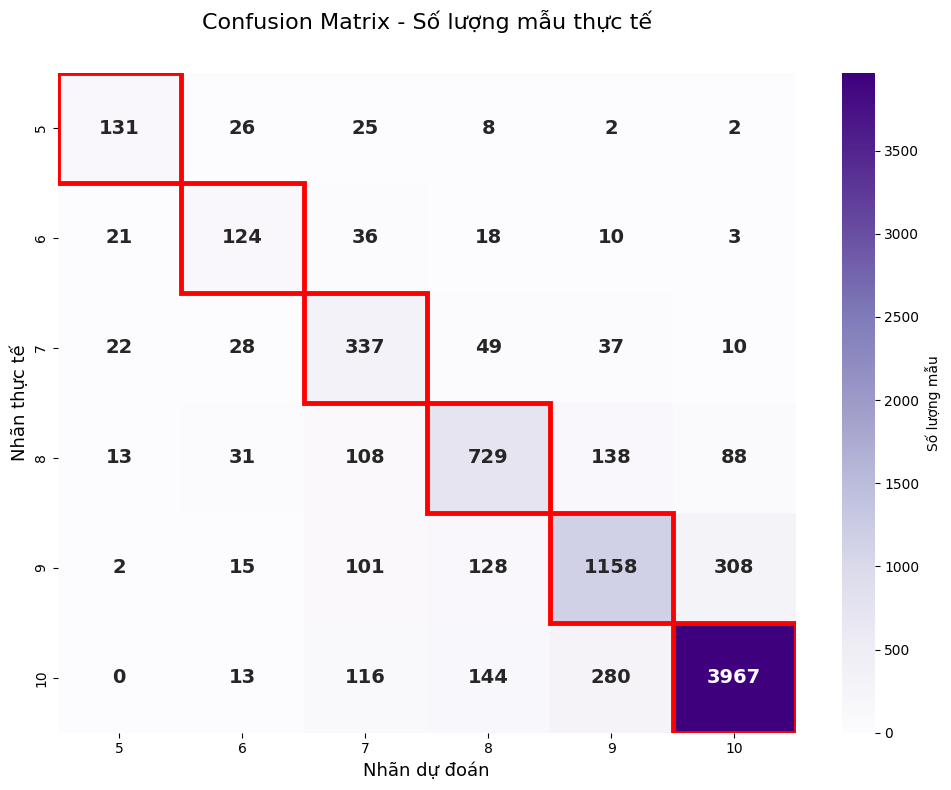

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Giả sử bạn đã có
# test_labels, test_preds là numpy array hoặc list

cm = confusion_matrix(test_labels, test_preds)

# Tên lớp: tùy bạn chọn một trong hai cách
class_names = ['5', '6', '7', '8', '9', '10']           # kiểu điểm số
# class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4', 'Class 5']

plt.figure(figsize=(10, 8))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Purples',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 14, "weight": "bold"},
            cbar_kws={'label': 'Số lượng mẫu'})

# Highlight đường chéo
for i in range(len(class_names)):
    plt.gca().add_patch(plt.Rectangle((i, i), 1, 1,
                                      fill=False, edgecolor='red', lw=3.5, zorder=10))

plt.title('Confusion Matrix - Số lượng mẫu thực tế\n', fontsize=16, pad=15)
plt.ylabel('Nhãn thực tế', fontsize=13)
plt.xlabel('Nhãn dự đoán', fontsize=13)
plt.tight_layout()
plt.show()

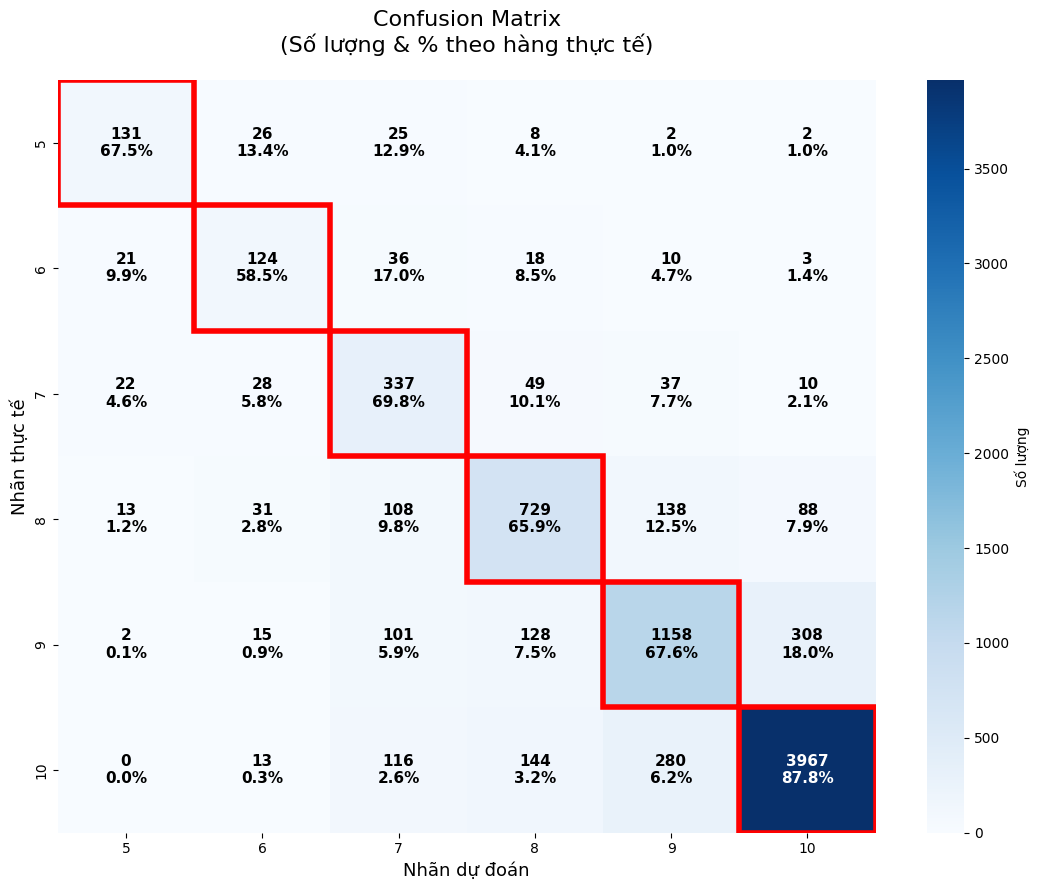

In [ ]:
import numpy as np

cm = confusion_matrix(test_labels, test_preds)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]  # chuẩn hóa theo hàng

class_names = ['5', '6', '7', '8', '9', '10']

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(cm, annot=False, cmap='Blues', ax=ax,
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Số lượng'})

# Vẽ text thủ công: số lượng + phần trăm
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        text = f"{cm[i,j]}\n{100*cm_percent[i,j]:.1f}%"
        ax.text(j+0.5, i+0.5, text,
                ha="center", va="center",
                color="white" if cm[i,j] > thresh else "black",
                fontsize=11, fontweight="bold")

ax.set_title("Confusion Matrix\n(Số lượng & % theo hàng thực tế)", fontsize=16, pad=20)
ax.set_ylabel("Nhãn thực tế", fontsize=13)
ax.set_xlabel("Nhãn dự đoán", fontsize=13)

# Đường chéo đỏ
for i in range(len(class_names)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor='red', lw=4, zorder=10))

plt.tight_layout()
plt.show()